# 1. ТЗ на резкий рост кликабельности

**1. Цель.** Понять, почему 20 июля 2026 года вырос CTR `top_search` на Android и что с этим делать.

**2. Гипотезы.** Либо сломался трекинг (например, клики записались дважды или часть показов потерялась), либо пользователи реально стали чаще кликать.

**3. Метрики.** CTR - доля показов, по которым был хотя бы один клик. Посмотрим на число показов и кликов, долю кликов без показа и конверсию из клика в отклик. Проверим, что будет с CTR после удаления дублей.

**4. Период.** Сравним 20 июля с остальными днями с 1 по 28 июля.

**5. Сегменты.** Смотрим `top_search` на Android. Для сравнения берём тот же формат на других платформах в те же дни.

**6. Критерий успеха.** Если всплеск пропадёт после исправления проблем в данных, это аргумент в пользу сбоя трекинга. Если останется, посмотрим, насколько CTR выбивается из обычного разброса и что произошло с откликами.

**7. Решение.** Если найдём сбой, чиним трекинг. Если данные укажут на реальный рост, проверяем изменение формата показа экспериментом. Если причина останется неясной, смотрим исходные логи за 20 июля.

**Глубина - разбор.** Если ошибиться, можно зря поменять формат показа. Формат можно откатить, а потерянные события не всегда получится восстановить. Проверим пропуски и повторы ID в таблицах показов, кликов и откликов. Для `top_search` на Android проверим, у всех ли кликов есть связанный показ. Сравним дневной CTR по платформам и покажем 95%-е доверительные интервалы для Android.

**Ожидаемый результат.** Короткая справка с CTR за 20 июля, сравнением с остальными днями и рекомендацией, что делать с форматом показа. Если данных для определения причины не хватит, укажем, что нужно проверить дальше.

# 2. Качество данных

In [17]:
import pandas as pd

impressions = pd.read_csv("impressions.csv", parse_dates=["event_date"])
clicks = pd.read_csv("clicks.csv", parse_dates=["event_date"])
responses = pd.read_csv("responses.csv", parse_dates=["event_date"])

checks = []
for name, df, id_col in [
    ("Показы", impressions, "impression_id"),
    ("Клики", clicks, "click_id"),
    ("Отклики", responses, "response_id"),
]:
    checks.append({
        "Таблица": name,
        "Строки": len(df),
        "Первая дата": df["event_date"].min(),
        "Последняя дата": df["event_date"].max(),
        "Повторы ID": df[id_col].dropna().duplicated().sum(),
        "Пропуски ID": df[id_col].isna().sum(),
        "Пропуски даты": df["event_date"].isna().sum(),
        "Пропуски платформы": df["platform"].isna().sum(),
        "Пропуски продукта": df["product"].isna().sum(),
    })

display(pd.DataFrame(checks))

,Таблица,Строки,Первая дата,Последняя дата,Повторы ID,Пропуски ID,Пропуски даты,Пропуски платформы,Пропуски продукта
0,Показы,80000,2026-07-01,2026-07-28,0,0,0,0,0
1,Клики,3837,2026-07-01,2026-07-28,0,0,0,0,0
2,Отклики,421,2026-07-01,2026-07-28,0,0,0,0,0


В данных за 1–28 июля 80 000 показов, 3 837 кликов и 421 отклик. Повторов ID событий и пропусков в проверенных полях нет.

In [18]:
android_clicks = clicks[
    (clicks["platform"] == "ANDROID") & (clicks["product"] == "top_search")
]

without_show = ~android_clicks["impression_id"].isin(impressions["impression_id"])

daily_check = (
    android_clicks.assign(without_show=without_show)
    .groupby("event_date")
    .agg(
        clicks=("click_id", "size"),
        clicks_without_show=("without_show", "sum"),
    )
)

daily_check["without_show_pct"] = (
    100 * daily_check["clicks_without_show"] / daily_check["clicks"]
).round(2)

display(daily_check)

,clicks,clicks_without_show,without_show_pct
event_date,,,
2026-07-01,16,0,0.0
2026-07-02,21,0,0.0
2026-07-03,29,0,0.0
2026-07-04,22,0,0.0
2026-07-05,21,0,0.0
2026-07-06,15,0,0.0
2026-07-07,14,0,0.0
2026-07-08,20,0,0.0
2026-07-09,26,0,0.0


# 3. Дневной CTR на Android


Проверим, сохраняется ли всплеск CTR, если каждый показ с хотя бы одним кликом считать один раз. Посчитаем CTR по дням и сравним 20 июля с остальными днями с 1 по 28 июля.

In [19]:
android_impressions = impressions[
    (impressions["platform"] == "ANDROID")
    & (impressions["product"] == "top_search")
].copy()

android_impressions["has_click"] = android_impressions["impression_id"].isin(
    android_clicks["impression_id"]
)

daily_ctr = android_impressions.groupby("event_date").agg(
    impressions=("impression_id", "size"),
    clicked_impressions=("has_click", "sum"),
)

daily_ctr["ctr_pct"] = (
    100 * daily_ctr["clicked_impressions"] / daily_ctr["impressions"]
).round(2)

display(daily_ctr)

,impressions,clicked_impressions,ctr_pct
event_date,,,
2026-07-01,599,16,2.67
2026-07-02,623,21,3.37
2026-07-03,683,29,4.25
2026-07-04,595,22,3.70
2026-07-05,666,21,3.15
2026-07-06,670,15,2.24
2026-07-07,644,14,2.17
2026-07-08,645,20,3.10
2026-07-09,598,26,4.35


20 июля CTR составил 9,40% (36 показов с кликом из 383). В остальные дни он был от 1,70% до 4,47%. Всплеск сохранился.

Теперь проверим, сопровождался ли рост CTR ростом откликов. Для каждого дня посчитаем, сколько кликов привели хотя бы к одному отклику и какую долю всех кликов за день они составили.

In [20]:
android_funnel = android_clicks.copy()

android_funnel["has_response"] = android_funnel["click_id"].isin(
    responses["click_id"]
)

daily_funnel = android_funnel.groupby("event_date").agg(
    clicks=("click_id", "size"),
    clicks_with_response=("has_response", "sum"),
)

daily_funnel["click_to_response_pct"] = (
    100 * daily_funnel["clicks_with_response"] / daily_funnel["clicks"]
).round(2)

display(daily_funnel)

,clicks,clicks_with_response,click_to_response_pct
event_date,,,
2026-07-01,16,3,18.75
2026-07-02,21,3,14.29
2026-07-03,29,3,10.34
2026-07-04,22,1,4.55
2026-07-05,21,3,14.29
2026-07-06,15,1,6.67
2026-07-07,14,3,21.43
2026-07-08,20,5,25.00
2026-07-09,26,4,15.38


20 июля из 36 кликов 4 привели к отклику. Конверсия из клика в отклик составила 11,11%. В другие дни до отклика доходили от 0 до 5 кликов. CTR 20 июля выделяется, а число кликов с откликом укладывается в обычный дневной разброс. Причину всплеска пока не установили.

Дальше покажем на графике, насколько CTR 20 июля отличается от дневных значений за остальные дни.

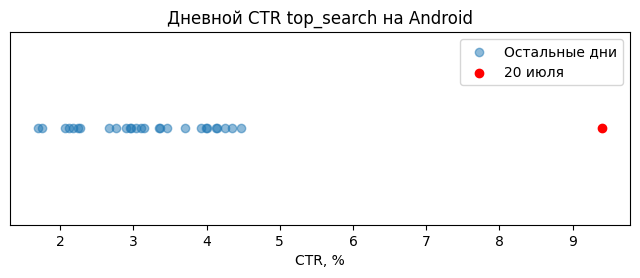

In [21]:
import matplotlib.pyplot as plt

july_20 = pd.Timestamp("2026-07-20")
other_days = daily_ctr.loc[daily_ctr.index != july_20, "ctr_pct"]

fig, ax = plt.subplots(figsize=(8, 2.5))
ax.scatter(other_days, [1] * len(other_days), alpha=0.5, label="Остальные дни")
ax.scatter(daily_ctr.loc[july_20, "ctr_pct"], 1, color="red", label="20 июля")

ax.set_title("Дневной CTR top_search на Android")
ax.set_xlabel("CTR, %")
ax.set_yticks([])
ax.legend()
plt.show()

На первом графике видно, что CTR 20 июля выделяется. Теперь добавим 95%-е доверительные интервалы, чтобы увидеть, насколько точно оценён CTR каждого дня.

In [22]:
import plotly.express as px
from statsmodels.stats.proportion import proportion_confint

daily_ci = daily_ctr.reset_index()
daily_ci["ctr"] = daily_ci["clicked_impressions"] / daily_ci["impressions"]

daily_ci["ci_low"], daily_ci["ci_high"] = proportion_confint(
    count=daily_ci["clicked_impressions"],
    nobs=daily_ci["impressions"],
    alpha=0.05,
    method="wilson",
)

daily_ci["error_up"] = daily_ci["ci_high"] - daily_ci["ctr"]
daily_ci["error_down"] = daily_ci["ctr"] - daily_ci["ci_low"]

fig = px.scatter(
    daily_ci,
    x="event_date",
    y="ctr",
    error_y="error_up",
    error_y_minus="error_down",
    title="Дневной CTR top_search на Android с 95%-ми интервалами",
    labels={"event_date": "Дата", "ctr": "CTR"},
)

fig.update_yaxes(tickformat=".0%")
fig.update_layout(
    width=850,
    height=290,
    font=dict(size=17),
    margin=dict(l=55, r=20, t=50, b=45),
)
fig.update_xaxes(tickformat="%d.%m")
fig.show()

In [23]:
bounds = daily_ci.loc[daily_ci["event_date"] == july_20, ["ci_low", "ci_high"]]
display((bounds * 100).round(2))

,ci_low,ci_high
19,6.87,12.74


20 июля CTR на Android составил 9,40%, а 95%-й интервал Уилсона - примерно от 6,9% до 12,7%. Это самый высокий дневной CTR за период. По графику видно, насколько выделяется этот день, а причину всплеска ещё нужно проверить.

Дальше посмотрим, был ли похожий скачок на других платформах.

In [24]:
top_search = impressions[impressions["product"] == "top_search"].copy()
top_search["has_click"] = top_search["impression_id"].isin(clicks["impression_id"])

platform_daily = (
    top_search.groupby(["event_date", "platform"])["has_click"]
    .mean()
    .mul(100)
    .unstack("platform")
)

july_20 = pd.Timestamp("2026-07-20")
other_days = platform_daily.drop(index=july_20)

platform_summary = pd.DataFrame({
    "CTR 20 июля, %": platform_daily.loc[july_20],
    "Медиана остальных дней, %": other_days.median(),
    "Максимум остальных дней, %": other_days.max(),
})

display(platform_summary.round(2))

,"CTR 20 июля, %","Медиана остальных дней, %","Максимум остальных дней, %"
platform,,,
ANDROID,9.40,3.10,4.47
DESKTOP_WEB,6.58,5.31,7.08
IOS,3.07,3.17,5.57
MOBILE_WEB,7.88,4.89,7.25


**Решение.** Формат `top_search` пока оставляем как есть. Сначала проверяем логи показов и кликов за 20 июля на Android и мобильном вебе.

**Что нашли.** 20 июля CTR на Android составил 9,40% при медиане 3,10% и максимуме 4,47% в остальные дни с 1 по 28 июля. 95%-й интервал Уилсона - от 6,87% до 12,74%. Все 36 кликов пришлись на разные показы, поэтому повторные записи кликов по одному показу всплеск не объясняют. Из 36 кликов 4 привели к отклику. Это укладывается в диапазон остальных дней - от 0 до 5 кликов с откликом.

На мобильном вебе CTR тоже превысил максимум остальных дней (7,88% против 7,25%). На iOS и десктопном вебе CTR остался в пределах наблюдавшихся значений.

**Ограничения.** По выгрузкам видно, что CTR вырос, но причина всплеска остаётся неизвестной. Чтобы понять, чаще ли пользователи кликали или изменилась запись событий, нужны исходные логи за 20 июля.

# *Бонус

Проверим, совпал ли всплеск CTR на Android 20 июля с заметным изменением расходов на top_search или top_boost. Для этого построим дневной расход по обоим форматам и отмечу на графике дату запуска top_boost и дату всплеска CTR.

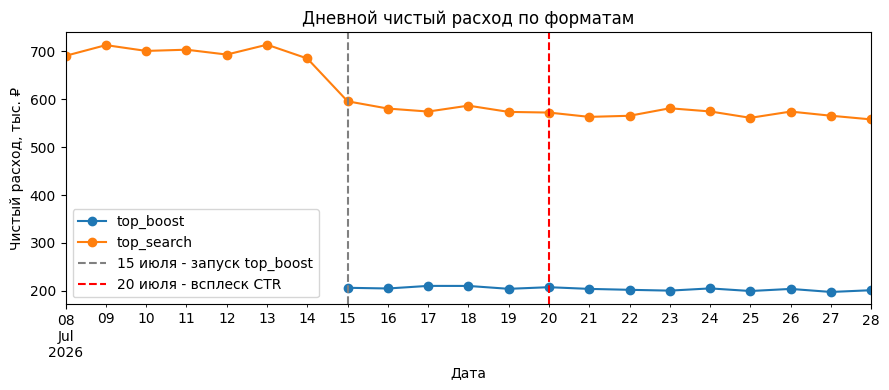

product,top_boost,top_search
event_date,,
2026-07-19,204.3,573.5
2026-07-20,207.7,572.1
2026-07-21,204.1,563.1


In [25]:
product_daily = pd.read_csv("product_daily.csv", parse_dates=["event_date"])

spend = product_daily[
    product_daily["product"].isin(["top_search", "top_boost"])
    & product_daily["event_date"].between("2026-07-08", "2026-07-28")
]

daily_spend = (spend.groupby(["event_date", "product"])["net_spend"].sum().unstack("product")
)

ax = (daily_spend / 1000).plot(figsize=(9, 4), marker="o")
ax.axvline(pd.Timestamp("2026-07-15"), color="gray", linestyle="--",
           label="15 июля - запуск top_boost")
ax.axvline(pd.Timestamp("2026-07-20"), color="red", linestyle="--",
           label="20 июля - всплеск CTR")
ax.set_title("Дневной чистый расход по форматам")
ax.set_xlabel("Дата")
ax.set_ylabel("Чистый расход, тыс. ₽")
ax.legend()
plt.tight_layout()
plt.show()

display((daily_spend.loc["2026-07-19":"2026-07-21"] / 1000).round(1))

In [26]:
top_search_spend = daily_spend["top_search"]

before = top_search_spend.loc["2026-07-08":"2026-07-14"].mean()
after = top_search_spend.loc["2026-07-15":"2026-07-21"].mean()

print(f"До запуска: {before / 1000:.1f} тыс. ₽ в день")
print(f"С даты запуска: {after / 1000:.1f} тыс. ₽ в день")
print(f"Снижение: {(before - after) / 1000:.1f} тыс. ₽ в день ({1 - after / before:.1%})")

До запуска: 699.8 тыс. ₽ в день
С даты запуска: 577.9 тыс. ₽ в день
Снижение: 121.9 тыс. ₽ в день (17.4%)


За первые семь дней с запуска `top_boost` средний дневной расход на `top_search` снизился на 17,4% по сравнению с предыдущими семью днями: с 699,8 до 577,9 тыс. ₽.

20 июля, в день всплеска CTR на Android, расходы на оба формата были близки к значениям 19 и 21 июля. Расходы в `product_daily.csv` приведены по формату в целом, поэтому динамику расходов отдельно на Android по этой выгрузке проверить нельзя.